# ST2195 Programming Coursework Part 2

Name: Darren Alexander



Before answering the part 2 questions, we will do an initiation of the notebook first. This process requires us to import relevant library packages for analysis as well as reading the given datasets.

In [1]:
import datetime as datetime
from datetime import date, timedelta

import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
from scipy import stats
import scipy.stats

import plotnine as p9
from plotnine import * 
import matplotlib.pyplot as plt

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

import seaborn as sns

In [2]:
plane_data = pd.read_csv("/Users/darren/Downloads/flight_dataset/plane-data.csv")
airport_data = pd.read_csv("/Users/darren/Downloads/flight_dataset/airports.csv")

In [3]:
flight2004 = pd.read_csv("/Users/darren/Downloads/flight_dataset/2004.csv.bz2", nrows = 10000)
flight2005 = pd.read_csv("/Users/darren/Downloads/flight_dataset/2005.csv.bz2", nrows = 10000)
flight2006 = pd.read_csv("/Users/darren/Downloads/flight_dataset/2006.csv.bz2", nrows = 10000)
flight2007 = pd.read_csv("/Users/darren/Downloads/flight_dataset/2007.csv.bz2", nrows = 10000)
flight2008 = pd.read_csv("/Users/darren/Downloads/flight_dataset/2008.csv.bz2", nrows = 10000)

In [4]:
flight2004.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10000 non-null  int64  
 1   Month              10000 non-null  int64  
 2   DayofMonth         10000 non-null  int64  
 3   DayOfWeek          10000 non-null  int64  
 4   DepTime            9667 non-null   float64
 5   CRSDepTime         10000 non-null  int64  
 6   ArrTime            9657 non-null   float64
 7   CRSArrTime         10000 non-null  int64  
 8   UniqueCarrier      10000 non-null  object 
 9   FlightNum          10000 non-null  int64  
 10  TailNum            10000 non-null  object 
 11  ActualElapsedTime  9657 non-null   float64
 12  CRSElapsedTime     10000 non-null  int64  
 13  AirTime            9657 non-null   float64
 14  ArrDelay           9657 non-null   float64
 15  DepDelay           9667 non-null   float64
 16  Origin             1000

In [5]:
flight2005.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10000 non-null  int64  
 1   Month              10000 non-null  int64  
 2   DayofMonth         10000 non-null  int64  
 3   DayOfWeek          10000 non-null  int64  
 4   DepTime            9565 non-null   float64
 5   CRSDepTime         10000 non-null  int64  
 6   ArrTime            9540 non-null   float64
 7   CRSArrTime         10000 non-null  int64  
 8   UniqueCarrier      10000 non-null  object 
 9   FlightNum          10000 non-null  int64  
 10  TailNum            10000 non-null  object 
 11  ActualElapsedTime  9540 non-null   float64
 12  CRSElapsedTime     10000 non-null  int64  
 13  AirTime            9540 non-null   float64
 14  ArrDelay           9540 non-null   float64
 15  DepDelay           9565 non-null   float64
 16  Origin             1000

In [6]:
flight2006.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10000 non-null  int64  
 1   Month              10000 non-null  int64  
 2   DayofMonth         10000 non-null  int64  
 3   DayOfWeek          10000 non-null  int64  
 4   DepTime            9804 non-null   float64
 5   CRSDepTime         10000 non-null  int64  
 6   ArrTime            9751 non-null   float64
 7   CRSArrTime         10000 non-null  int64  
 8   UniqueCarrier      10000 non-null  object 
 9   FlightNum          10000 non-null  int64  
 10  TailNum            10000 non-null  object 
 11  ActualElapsedTime  9751 non-null   float64
 12  CRSElapsedTime     10000 non-null  int64  
 13  AirTime            9751 non-null   float64
 14  ArrDelay           9751 non-null   float64
 15  DepDelay           9804 non-null   float64
 16  Origin             1000

In [7]:
flight2007.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10000 non-null  int64  
 1   Month              10000 non-null  int64  
 2   DayofMonth         10000 non-null  int64  
 3   DayOfWeek          10000 non-null  int64  
 4   DepTime            9893 non-null   float64
 5   CRSDepTime         10000 non-null  int64  
 6   ArrTime            9886 non-null   float64
 7   CRSArrTime         10000 non-null  int64  
 8   UniqueCarrier      10000 non-null  object 
 9   FlightNum          10000 non-null  int64  
 10  TailNum            10000 non-null  object 
 11  ActualElapsedTime  9886 non-null   float64
 12  CRSElapsedTime     10000 non-null  int64  
 13  AirTime            9886 non-null   float64
 14  ArrDelay           9886 non-null   float64
 15  DepDelay           9893 non-null   float64
 16  Origin             1000

In [8]:
flight2008.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10000 non-null  int64  
 1   Month              10000 non-null  int64  
 2   DayofMonth         10000 non-null  int64  
 3   DayOfWeek          10000 non-null  int64  
 4   DepTime            9837 non-null   float64
 5   CRSDepTime         10000 non-null  int64  
 6   ArrTime            9811 non-null   float64
 7   CRSArrTime         10000 non-null  int64  
 8   UniqueCarrier      10000 non-null  object 
 9   FlightNum          10000 non-null  int64  
 10  TailNum            9837 non-null   object 
 11  ActualElapsedTime  9811 non-null   float64
 12  CRSElapsedTime     10000 non-null  int64  
 13  AirTime            9811 non-null   float64
 14  ArrDelay           9811 non-null   float64
 15  DepDelay           9837 non-null   float64
 16  Origin             1000

After checking the details of the imported datasets, we found out that some years have different datatype on few of their columns. Due to that, we have to adjust and make them all the same. This can be achieved through loops, where the columns that are not numerical datatype (such as object) will be change. Additionally, we will also fill the missing value on these columns with 0.

In [9]:
for col in flight2004:
    if flight2004[col].dtypes == 'float64':
        flight2004[col] = flight2004[col].fillna(0)
        flight2004[col] = flight2004[col].astype('int64')

In [10]:
for col in flight2005:
    if flight2005[col].dtypes == 'float64':
        flight2005[col] = flight2005[col].fillna(0)
        flight2005[col] = flight2005[col].astype('int64')

In [11]:
for col in flight2006:
    if flight2006[col].dtypes == 'float64':
        flight2006[col] = flight2006[col].fillna(0)
        flight2006[col] = flight2006[col].astype('int64')

In [12]:
for col in flight2007:
    if flight2007[col].dtypes == 'float64':
        flight2007[col] = flight2007[col].fillna(0)
        flight2007[col] = flight2007[col].astype('int64')

In [13]:
for col in flight2008:
    if flight2008[col].dtypes == 'float64':
        flight2008[col] = flight2008[col].fillna(0)
        flight2008[col] = flight2008[col].astype('int64')

In [14]:
flight2008.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               10000 non-null  int64 
 1   Month              10000 non-null  int64 
 2   DayofMonth         10000 non-null  int64 
 3   DayOfWeek          10000 non-null  int64 
 4   DepTime            10000 non-null  int64 
 5   CRSDepTime         10000 non-null  int64 
 6   ArrTime            10000 non-null  int64 
 7   CRSArrTime         10000 non-null  int64 
 8   UniqueCarrier      10000 non-null  object
 9   FlightNum          10000 non-null  int64 
 10  TailNum            9837 non-null   object
 11  ActualElapsedTime  10000 non-null  int64 
 12  CRSElapsedTime     10000 non-null  int64 
 13  AirTime            10000 non-null  int64 
 14  ArrDelay           10000 non-null  int64 
 15  DepDelay           10000 non-null  int64 
 16  Origin             10000 non-null  object

After the data cleaning process is done, we will merge all the different years data into one big dataset

In [15]:
# Merging the datasets
dfmerge = flight2004._append(flight2005,ignore_index=True)

In [16]:
display(dfmerge)

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2004,1,12,1,623,630,901,915,UA,462,...,7,11,0,NaN,0,0,0,0,0,0
1,2004,1,13,2,621,630,911,915,UA,462,...,16,16,0,NaN,0,0,0,0,0,0
2,2004,1,14,3,633,630,920,915,UA,462,...,4,15,0,NaN,0,0,0,0,0,0
3,2004,1,15,4,627,630,859,915,UA,462,...,4,10,0,NaN,0,0,0,0,0,0
4,2004,1,16,5,635,630,918,915,UA,462,...,3,13,0,NaN,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,2005,1,28,5,1029,1030,1541,1543,UA,902,...,7,20,0,NaN,0,0,0,0,0,0
19996,2005,1,29,6,1028,1030,1536,1543,UA,902,...,6,16,0,NaN,0,0,0,0,0,0
19997,2005,1,30,7,1030,1030,1540,1543,UA,902,...,8,19,0,NaN,0,0,0,0,0,0
19998,2005,1,31,1,1030,1030,1532,1543,UA,902,...,8,13,0,NaN,0,0,0,0,0,0


In [17]:
dfmerge = dfmerge._append(flight2006,ignore_index=True)
dfmerge = dfmerge._append(flight2007,ignore_index=True)
dfmerge = dfmerge._append(flight2008,ignore_index=True)

In [18]:
display(dfmerge)

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2004,1,12,1,623,630,901,915,UA,462,...,7,11,0,NaN,0,0,0,0,0,0
1,2004,1,13,2,621,630,911,915,UA,462,...,16,16,0,NaN,0,0,0,0,0,0
2,2004,1,14,3,633,630,920,915,UA,462,...,4,15,0,NaN,0,0,0,0,0,0
3,2004,1,15,4,627,630,859,915,UA,462,...,4,10,0,NaN,0,0,0,0,0,0
4,2004,1,16,5,635,630,918,915,UA,462,...,3,13,0,NaN,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2008,1,6,7,1111,1055,1326,1310,WN,583,...,3,19,0,NaN,0,0,0,0,0,16
49996,2008,1,6,7,1814,1725,2041,1940,WN,637,...,3,30,0,NaN,0,25,0,12,0,24
49997,2008,1,6,7,714,720,927,935,WN,1059,...,4,14,0,NaN,0,0,0,0,0,0
49998,2008,1,6,7,1417,1320,1633,1535,WN,1918,...,3,16,0,NaN,0,2,0,1,0,55


In [19]:
dfmerge.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2004,1,12,1,623,630,901,915,UA,462,...,7,11,0,NaN,0,0,0,0,0,0
1,2004,1,13,2,621,630,911,915,UA,462,...,16,16,0,NaN,0,0,0,0,0,0
2,2004,1,14,3,633,630,920,915,UA,462,...,4,15,0,NaN,0,0,0,0,0,0
3,2004,1,15,4,627,630,859,915,UA,462,...,4,10,0,NaN,0,0,0,0,0,0
4,2004,1,16,5,635,630,918,915,UA,462,...,3,13,0,NaN,0,0,0,0,0,0


After all the initiation is completed, now we can start to answer the questions.

### Question 2a. (What are the best times and days of the week to minimise delays each year?)

Question Part 2a instruct us to use the given attributes from the datasets to show the best time and days of the week in minimizing the delays each year. The attributes that are going to be use are: DayOfWeek as the attribute that holds which day the flight happened, CRSDepTime as the attribute that holds the scheduled departure time, and any attributes that show how that specific flight run into delay.

Additionally, as the main focus is to minimize delays, we will also use DepDelay as the attribute that holds the amount of minutes that specific flights got delayed. This is chosen due to the departure delay is most likely that makes the passenger complains and remember the specific delay.

Besides that, we will also make a new attribute in determining whether a flight got delayed or not, considering no matter how big or small it is. This attribute is called Delayed, where it s a categorical attribute that holds one if it is a delayed flights, and zero if it is not.

In [20]:
df_DayTime = dfmerge[['DayOfWeek','CRSDepTime','DepDelay']]
# Finding out which flights have DepDelay
def delayed(DepDelay):
    if DepDelay > 0:
        return 1
    else:
        return 0

Delayed_list = []

for DepDelay in df_DayTime['DepDelay']:
    Delay = delayed(DepDelay)
    Delayed_list.append(Delay)

df_DayTime['Delayed'] = Delayed_list

The next step will be grouping all the flights on each days and timeframes. These timeframes will divide the 24 hours into a more bounded group, consisted of: Morning (5:00 to 12:00), Afternoon (12:00 to 17:00), Evening (17:00 to 21:00), and Night (21:00 to 5:00) flights.

Additionally, we will also map the DayOfWeek attribute into their respective days, not just their numerical version. Then group them up, so the delays on each days is easier to count.

In [21]:
# Determining the best day of the week to minimise flight delays

# map days
df_BestDay = df_DayTime
map_day = {1:'Monday',2:'Tuesday', 3:'Wednesday',4:'Thursday',5:'Friday', 6:'Saturday',7:'Sunday'}
index_day = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

df_BestDay['DayOfWeek'] = df_DayTime['DayOfWeek']
df_BestDay['DayOfWeek'] = df_BestDay['DayOfWeek'].map(map_day).astype('str')

df_BestDay['DayOfWeek'] = pd.Categorical(df_BestDay['DayOfWeek'], categories=index_day)
df_BestDay = df_BestDay.sort_values('DayOfWeek')

bestday_look = df_BestDay.groupby(['DayOfWeek'], observed=True)
bestday_look.head()

,DayOfWeek,CRSDepTime,DepDelay,Delayed
0,Monday,630,-7,0
28337,Monday,1409,41,1
28338,Monday,615,29,1
28339,Monday,1535,21,1
28340,Monday,935,-3,0
29300,Tuesday,1905,-3,0
29299,Tuesday,1714,5,1
29069,Tuesday,1600,-6,0
28856,Tuesday,1145,-4,0
29302,Tuesday,1350,-4,0


In [22]:
bestday_look['Delayed'].count()

DayOfWeek
Monday        4730
Tuesday       7382
Wednesday     7486
Thursday     10176
Friday        7953
Saturday      6795
Sunday        5478
Name: Delayed, dtype: int64

In [23]:
df_BestDay['DayOfWeek']

0        Monday
28337    Monday
28338    Monday
28339    Monday
28340    Monday
          ...  
14923    Sunday
14932    Sunday
14941    Sunday
14880    Sunday
49999    Sunday
Name: DayOfWeek, Length: 50000, dtype: category
Categories (7, object): ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

After that, we will start to visualize the graph amount of delay that happens at each days

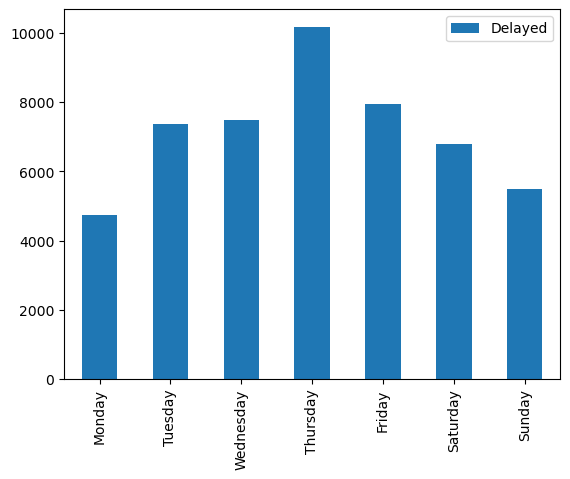

In [24]:
# Visualize the graph
df = pd.DataFrame(data=bestday_look['Delayed'].count(), index=bestday_look.groups.keys())
fig = df.plot(kind = 'bar')

From the output bar graph it shows that since Monday to Sunday amount of flights delayed increase steadily until Thursday, eventually decreasing consistently until Sunday. Additionally, as the main target is to find the best days of the week in minimizing the delays, the illustration indicates that on Monday amount of delayed flights is at it lowest compare to any other days.

After finding the day which give the lowest amount of delayed flights, we will start to do the same steps on the timeframes.

In [25]:
# Best time of day to fly in minimising the delay
df_BestTime = df_DayTime
# Four time frames is selected for time of day
def find_time(CRSDepTime):
    if CRSDepTime in range(500,1200):
        return "Morning"
    elif CRSDepTime in range(1200, 1700):
        return "Afternoon"
    elif CRSDepTime in range(1700, 2100):
        return "Evening"
    else:
        return "Night"

TimeofDay_list =[]

for CRSDepTime in df_BestTime['CRSDepTime']:
    TimeofDay = find_time(CRSDepTime)
    TimeofDay_list.append(TimeofDay)

df_BestTime['TimeofDay'] = TimeofDay_list

In [26]:
df_BestTime.head()

,DayOfWeek,CRSDepTime,DepDelay,Delayed,TimeofDay
0,Monday,630,-7,0,Morning
1,Tuesday,630,-9,0,Morning
2,Wednesday,630,3,1,Morning
3,Thursday,630,-3,0,Morning
4,Friday,630,5,1,Morning


In [27]:
# map_time = {1:'Morning',2:'Afternoon', 3:'Evening',4:'Night'}
index_time = ['Morning', 'Afternoon', 'Evening', 'Night']

df_BestTime['TimeofDay'] = pd.Categorical(df_BestTime['TimeofDay'], categories=index_time)
df_BestTime = df_BestTime.sort_values('TimeofDay')

df_BestTime = df_BestTime.groupby(['TimeofDay'], observed=True)
df_BestTime.head()

,DayOfWeek,CRSDepTime,DepDelay,Delayed,TimeofDay
0,Monday,630,-7,0,Morning
26062,Sunday,935,245,1,Morning
26060,Sunday,750,-1,0,Morning
26058,Sunday,800,-6,0,Morning
26056,Sunday,635,1,1,Morning
29324,Tuesday,1545,-9,0,Afternoon
27887,Monday,1650,-7,0,Afternoon
8217,Tuesday,1600,-10,0,Afternoon
43229,Friday,1225,29,1,Afternoon
29072,Tuesday,1612,-4,0,Afternoon


Afer that, we will start to visualize the graph of amount of delays in each timeframes.

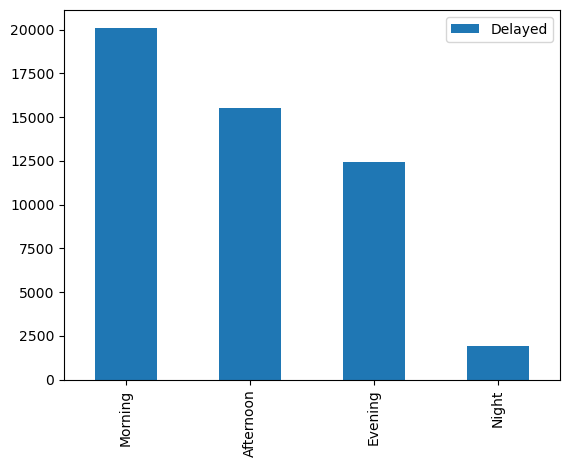

In [28]:
df = pd.DataFrame(data=df_BestTime['Delayed'].count(), index=df_BestTime.groups.keys())
fig = df.plot(kind = 'bar')

The graph above shows that the delay happens less as the day goes by, with night flights has nearly 1/8 the morning delays.

In conclusion, the best time and days of the week in minimizing the delays will be choosing the night flight around 21.00 to 05.00 on Monday.

### Question 2b. (Evaluate whether older planes suffer more delays on a year-to-year basis)

Question Part 2b instruct us to evaluate on aircraft/plane's age and see if they receive more delay than the newer aircrafts. However, due to the data about aircraft age lies on a different datasets, we need to join them first. Then, we can start to evaluate aircraft age connection with delays.

In [29]:
# plane_data = pd.read_csv("/Users/darren/Downloads/flight_dataset/plane-data.csv")
plane_data = plane_data[['year','tailnum']]

In [30]:
for col in plane_data:
    plane_data.dropna(subset=['year'], inplace=True)
for col in plane_data:
    plane_data[col] = plane_data[col].fillna(0)
plane_data.head()

,year,tailnum
34,2004.0,N10156
35,1998.0,N102UW
36,1986.0,N10323
37,1999.0,N103US
38,1998.0,N104UA


In [31]:
dfAge_Delays = dfmerge[['TailNum', 'Year']]
dfAge_Delays.head()

,TailNum,Year
0,N805UA,2004
1,N851UA,2004
2,N436UA,2004
3,N828UA,2004
4,N831UA,2004


In this step, we will use the categorical delay data in the Delayed attributes to tell if a flights run into delays or not.

In [32]:
# Create the AircraftAge_Delays table for analysis 
dfAge_Delays['Delayed'] = df_DayTime['Delayed']

In [33]:
# Join the AircraftAge_Delays table with planes table
dfAge_Delays = pd.merge(dfAge_Delays, plane_data, left_on = 'TailNum', right_on = 'tailnum')

# Create a new attibutes to hold Aircraft Age
dfAge_Delays['AircraftAge'] = (dfAge_Delays['Year'] - dfAge_Delays['year'])
dfAge_Delays.head()

,TailNum,Year,Delayed,year,tailnum,AircraftAge
0,N805UA,2004,0,1998.0,N805UA,6.0
1,N851UA,2004,0,2002.0,N851UA,2.0
2,N436UA,2004,1,1996.0,N436UA,8.0
3,N828UA,2004,0,1999.0,N828UA,5.0
4,N831UA,2004,1,2000.0,N831UA,4.0


In [34]:
dfAge_Delays.groupby(['AircraftAge'])['Delayed'].count()

AircraftAge
1.0      892
2.0     1103
3.0     1604
4.0     1790
5.0     1366
6.0     1986
7.0     2241
8.0     1404
9.0     1462
10.0    1334
11.0    1409
12.0    2415
13.0    2904
14.0    2216
15.0    1792
16.0    2092
17.0    2328
18.0    1119
19.0    1126
20.0     514
21.0     468
22.0     888
23.0     558
24.0      50
33.0      19
41.0      16
Name: Delayed, dtype: int64

In [35]:
# Data cleaning for easier process

dfAge_Delays = dfAge_Delays.query("AircraftAge >= 0 & AircraftAge <= 27")

dfAge_Delays['AircraftAge'].dropna()
dfAge_Delays['Delayed'].dropna()

0        0
1        0
2        1
3        0
4        1
        ..
35091    1
35092    1
35093    0
35094    1
35095    1
Name: Delayed, Length: 35061, dtype: int64

After that, we will group each aircraft age.

In [36]:
# Grouping for each Aircraft Age
age_delay = dfAge_Delays.groupby(['AircraftAge'])
age_delay.head()

,TailNum,Year,Delayed,year,tailnum,AircraftAge
0,N805UA,2004,0,1998.0,N805UA,6.0
1,N851UA,2004,0,2002.0,N851UA,2.0
2,N436UA,2004,1,1996.0,N436UA,8.0
3,N828UA,2004,0,1999.0,N828UA,5.0
4,N831UA,2004,1,2000.0,N831UA,4.0
...,...,...,...,...,...,...
25598,N302SW,2008,1,1984.0,N302SW,24.0
25641,N301SW,2008,1,1984.0,N301SW,24.0
25714,N302SW,2008,1,1984.0,N302SW,24.0
25819,N302SW,2008,0,1984.0,N302SW,24.0


Next step, we will visualize the graph that shows the amount of delay that happens for each aircraft age.

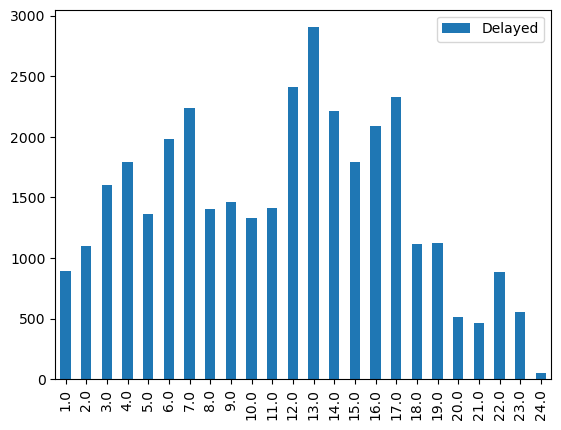

In [37]:
df = pd.DataFrame(data=age_delay['Delayed'].count(), index=age_delay.groups.keys())
fig = df.plot(kind = 'bar')

Due to every age have more than one amount of delay, we couldn't apply the Spearman Correlation. Hence, we will try to use the Point-Biserial Correlation. However, to apply the use of Point-Biseral Correlation, first we need to fulfill few assumptions. Each assumptions will be solve in the line below.

#### First Assumption: Does the two variables follow a normal distribution?

In answering the first assumption, We will conduct the Shapiro-Wilk normality test using stats.shapiro() to test normality of the two variables.

Formulating the hypothesis below:

H0: The data are normally distributed

H1: The data are not normally distributed

We will also set a significance level of 5% and reject the null hypothesis if the p-value of the test is less than 0.05

In [38]:
# Normality test for Aircraft Age
stats.shapiro(dfAge_Delays["AircraftAge"])

/Applications/anaconda3/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 35061.


ShapiroResult(statistic=0.9724265241772688, pvalue=6.51697296607512e-61)

In [39]:
# Normality test for probability of Delay
stats.shapiro(dfAge_Delays["Delayed"])

ShapiroResult(statistic=0.6350756002265551, pvalue=7.8332400869064e-123)

The p-value of aircraft age shows a number of 6.51697296607512e-61, while the p-value of delayed departure shows a number of 7.8332400869064e-123  

From this given p-value, we can see that both p-values are much lower than the significance level of 5%. Hence, we can conclude that both attributes does not follow a normal distribution. This means we cannot use the Point-Biserial Correlation to directly answer the question.

However, we can still try to look for their correlation further using a simple visualization.

#### Second Assumption: Do both variable have similar spread (variance)?

In [40]:
temp_delay = dfAge_Delays.copy()
temp_delay.drop(columns=['TailNum', 'Year', 'year', 'tailnum'], axis = 1, inplace=True)
temp_delay = temp_delay.groupby('Delayed')
temp_delay_less = temp_delay.get_group(0)
temp_delay_full = temp_delay.get_group(1)

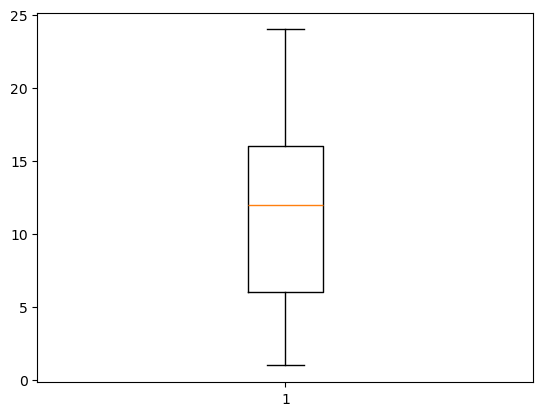

In [41]:
plt.boxplot(temp_delay_less['AircraftAge'])
plt.show()

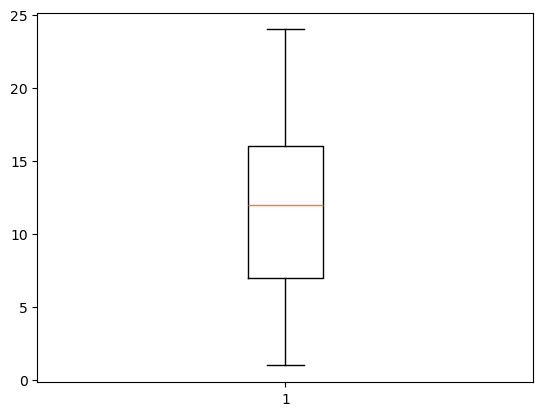

In [42]:
plt.boxplot(temp_delay_full['AircraftAge'])
plt.show()

To reiterate the same variance shown on both boxplot, we can try to find the mean and standard deviation for each group.

In [43]:
print(
    'std of plane age with no delay', temp_delay_less['AircraftAge'].std(), '\n',
'mean of plane age with no delay', temp_delay_less['AircraftAge'].mean(), '\n',
    'std of plane age with delay', temp_delay_full['AircraftAge'].std(), '\n',
'mean of plane age with delay', temp_delay_full['AircraftAge'].mean()
)

std of plane age with no delay 5.372623676200539 
 mean of plane age with no delay 11.195093671813023 
 std of plane age with delay 5.934753992860909 
 mean of plane age with delay 11.362107743386527


From the output number of mean and standard deviation above, it shows that the mean and standard deviation for aircraft age with no delay is 11.195093671813023 and 5.372623676200539 respectively. While, the mean and standard deviation for aircraft age with delay is 11.362107743386527 and 5.934753992860909. Hence, we can conclude that both the aircraft age and the delays have a small and similar variance.

#### Finally, calculate the Point-Biserial Correlation to determine whether they are related or not.

In [44]:
x = dfAge_Delays["AircraftAge"]
y = dfAge_Delays["Delayed"]


# Calculate the point biserial correlation coefficient
from scipy.stats import pointbiserialr
corr, p = pointbiserialr(x, y)

print("Point biserial correlation coefficient:", corr)
print("p-value:", p)

Point biserial correlation coefficient: 0.014672174918676202
p-value: 0.006007835031527582


Although the assumptions for correlation is already falls off, however, when we try to keep doing the Point biserial Correlation, we can easily see from the illustration above that a coefficient of 1.47% and p value of 0.006008 is so small, indicating aircraft age and the delay of an aircraft is not correlated.

Despite that, we will try to look further for correlation using a simple visualization.

#### Firstly, we will try to see the graph of regression line of the sum of all delay for each aircraft age.

In [45]:
temp = dfAge_Delays.groupby(['AircraftAge'])

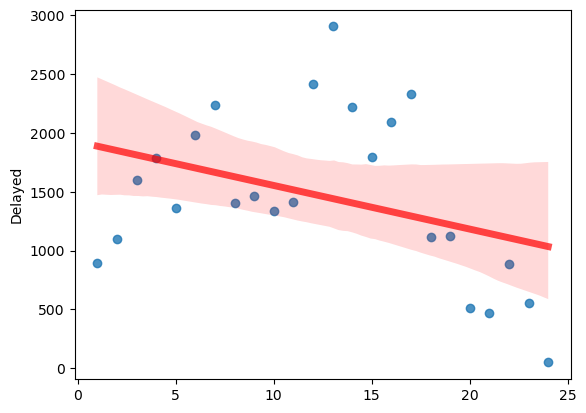

In [46]:
sns.regplot(x = list(temp.groups.keys()), y = temp["Delayed"].count(), line_kws={"color":"r","alpha":0.7,"lw":5})
plt.show()

From the regression graph above, it shows the sums of all delay and non-delay in each flight age. However, it isn't enough to make any conclusion based on it. To solve this underlying issue, we will use the total amount or means of delay of each aircraft age.

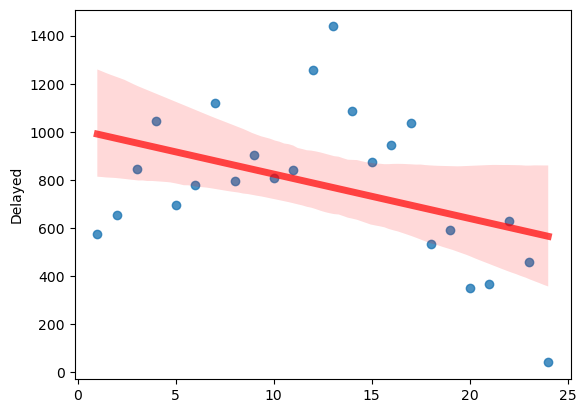

In [47]:
# Sum of All Delay and Non-Delay
sns.regplot(x = list(temp.groups.keys()), y = temp["Delayed"].sum(), line_kws={"color":"r","alpha":0.7,"lw":5})
plt.show()

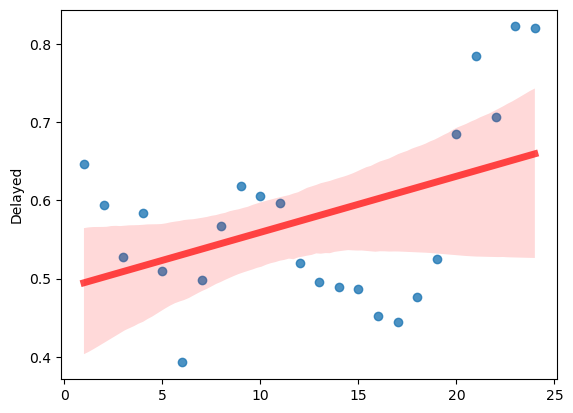

In [48]:
# The Average Delay
sns.regplot(x = list(temp.groups.keys()), y = temp["Delayed"].mean(), line_kws={"color":"r","alpha":0.7,"lw":5})
plt.show()

From both regression line graph above, it shows that the average number of delay happen more often on older aircrafts compare to new aircrafts. However,if we look at the total number of delay flight for each age, it can be seen that on number of delay flight in older aircrafts is much lower than newer aircrafts.

#### This can mean two things:

1. The older planes indeed suffer more delay in average numbers, but as flights using older plane will be less in numbers, the actual total delay of older planes will be fewer considering that most flights will be using a newer aircrafts.
2. Aircraft's age cannot be said to be directly correlated with flight's delay, as there is much factor beside aircraft age and number of flight delay that need to be consider in making an accurate analysis.

#### In conclusion to answering Part 2b question, older planes cannot be truly said that they suffer more delays on a year-to-year basis.

Conducting an oversampling could not exactly evaluate that older planes suffer more delay as it is a fact that flight with older planes with happen less frequently. Additionally, cutting the age of the counted aircrafts to below age of 20 is not possible. As based on this reference, aircraft is stated as old when they reach the age of 20 or above.

reference for aircraft age: 
<https://insijets.com/blog/does-the-age-of-an-aircraft-affect-its-safety>

### Question 2c. (For each year, fit a logistic model for the probability of diverted US flights using as many features as possible from attributes of the departure date, the scheduled departure and arrival times, the coordinates and distance between departure and planned arrival airports, and the carrier. Visualize the coefficients across years.)

Question Part 2c instruct us to visualize the coefficients of a logistic regression model using few given attributes from the question. These attributes are: departure date, the scheduled departure and arrival times, the coordinates and distance between departure and planned arrival airports, and the carrier.

To answer this question, we will fit a logistic regression using the properties (predicted and predictors) given by the question. Before starting to answer the question, the first step we need to do is to do data preparation, as the required attributes (predictors) are in a difference datasets.

In this question, the predicted attributes are the diverted data in diverted column. Where as the predictors attributes are DayofMonth as the flight's date, CRSDepTime and CRSArrTime as the scheduled and arrival time, Distance as the flight's distance, UniqueCarrier as the name of the flight's airline name, Origin and Dest as the flight origin and destination with their airport's coordinates.

In [49]:
# airport_data = pd.read_csv("/Users/darren/Downloads/flight_data/airports.csv")
airport_data = airport_data[['iata', 'lat', 'long']]

In [50]:
# Identifying and merging the predictors
dfDiverted_Flight = dfmerge[['DayofMonth', 'CRSDepTime', 'CRSArrTime', 'Distance', 'UniqueCarrier', 'Origin']]

In [51]:
dfDiverted_Flight = pd.merge(dfDiverted_Flight, airport_data, left_on = 'Origin', right_on = 'iata')

In [52]:
dfDiverted_Flight.rename(columns = {'iata':'Originiata', 'lat':'Originlat', 'long':'Originlong'}, inplace = True)

In [53]:
dfDiverted_Flight['Dest'] = dfmerge[['Dest']]
dfDiverted_Flight.head()

,DayofMonth,CRSDepTime,CRSArrTime,Distance,UniqueCarrier,Origin,Originiata,Originlat,Originlong,Dest
0,12,630,915,599,UA,ORD,ORD,41.979595,-87.904464,CLT
1,13,630,915,599,UA,ORD,ORD,41.979595,-87.904464,CLT
2,14,630,915,599,UA,ORD,ORD,41.979595,-87.904464,CLT
3,15,630,915,599,UA,ORD,ORD,41.979595,-87.904464,CLT
4,16,630,915,599,UA,ORD,ORD,41.979595,-87.904464,CLT


In [54]:
dfDiverted_Flight = pd.merge(dfDiverted_Flight, airport_data, left_on = 'Dest', right_on = 'iata')

In [55]:
dfDiverted_Flight.rename(columns = {'iata':'Destiata', 'lat':'Destlat', 'long':'Destlong'}, inplace = True)

Discard/drop the replicated column/attributes to make the dataframe cleaner

In [56]:
dfDiverted_Flight = dfDiverted_Flight.drop('Destiata', axis=1)
dfDiverted_Flight = dfDiverted_Flight.drop('Originiata', axis=1)

In [57]:
dfDiverted_Flight.head()

,DayofMonth,CRSDepTime,CRSArrTime,Distance,UniqueCarrier,Origin,Originlat,Originlong,Dest,Destlat,Destlong
0,12,630,915,599,UA,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126
1,13,630,915,599,UA,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126
2,14,630,915,599,UA,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126
3,15,630,915,599,UA,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126
4,16,630,915,599,UA,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126


In [58]:
dfDiverted_Flight['Diverted'] = dfmerge[['Diverted']]

# Divide the essential data for later purposes
tempEssential = dfDiverted_Flight[['DayofMonth', 'CRSDepTime', 'CRSArrTime', 'Distance', 'Originlat', 'Originlong', 'Destlat', 'Destlong', 'Diverted']].copy()
tempEssential.head()

,DayofMonth,CRSDepTime,CRSArrTime,Distance,Originlat,Originlong,Destlat,Destlong,Diverted
0,12,630,915,599,41.979595,-87.904464,35.214011,-80.943126,0
1,13,630,915,599,41.979595,-87.904464,35.214011,-80.943126,0
2,14,630,915,599,41.979595,-87.904464,35.214011,-80.943126,0
3,15,630,915,599,41.979595,-87.904464,35.214011,-80.943126,0
4,16,630,915,599,41.979595,-87.904464,35.214011,-80.943126,0


In [59]:
# Making sure the diverted column is integrated successfully
dfDiverted_Flight.loc[dfDiverted_Flight['Diverted'] == 1]

,DayofMonth,CRSDepTime,CRSArrTime,Distance,UniqueCarrier,Origin,Originlat,Originlong,Dest,Destlat,Destlong,Diverted
280,18,725,933,1671,UA,MSY,29.993389,-90.258028,LAX,33.942536,-118.408074,1
435,4,1950,2212,1726,UA,ORD,41.979595,-87.904464,SNA,33.675659,-117.868223,1
2190,9,2120,2340,1721,UA,ORD,41.979595,-87.904464,SEA,47.448982,-122.309313,1
2292,3,1845,1910,419,UA,ICT,37.649959,-97.433046,DEN,39.858408,-104.667002,1
2887,24,1445,1711,802,UA,ORD,41.979595,-87.904464,DFW,32.895951,-97.037200,1
...,...,...,...,...,...,...,...,...,...,...,...,...
47472,5,1435,1650,1680,WN,MDW,41.785983,-87.752424,RNO,39.498576,-119.768065,1
47802,5,1420,1540,444,WN,PDX,45.588722,-122.597500,RNO,39.498576,-119.768065,1
47971,5,1430,1520,601,WN,PHX,33.434167,-112.008056,RNO,39.498576,-119.768065,1
48694,5,1455,1510,367,WN,TUS,32.116083,-110.941028,SAN,32.733556,-117.189657,1


As logistics regression requires all predictors to be numerical, hence, all the categorical data have to be change. In doing this process, we will create dummy variables. The attributes that will be change into dummy variables are UniqueCarrier, Origin, and Dest.

In [60]:
# UniqueCarrier
Carrier = pd.get_dummies(dfDiverted_Flight, columns =['UniqueCarrier'], drop_first = True)
Carrier.head()

,DayofMonth,CRSDepTime,CRSArrTime,Distance,Origin,Originlat,Originlong,Dest,Destlat,Destlong,Diverted,UniqueCarrier_US,UniqueCarrier_WN
0,12,630,915,599,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126,0,False,False
1,13,630,915,599,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126,0,False,False
2,14,630,915,599,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126,0,False,False
3,15,630,915,599,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126,0,False,False
4,16,630,915,599,ORD,41.979595,-87.904464,CLT,35.214011,-80.943126,0,False,False


Divide the Carrier dummy and Airport dummy to look at their data separately.

In [61]:
# Origin
Origin = pd.get_dummies(dfDiverted_Flight, columns =['Origin'], drop_first = True)

In [62]:
# Dest
# Destination Airport's dummy creation is combined with Origin Airport as they have similar function and attributes.
# For now, the variable is called Dest temporaryly.
Dest = pd.get_dummies(Origin, columns =['Dest'], drop_first = True)

In [63]:
Dest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Columns: 217 entries, DayofMonth to Dest_TUS
dtypes: bool(207), float64(4), int64(5), object(1)
memory usage: 13.7+ MB


In [64]:
pd.pandas.set_option('display.max_columns', None)
Dest.head()

,DayofMonth,CRSDepTime,CRSArrTime,Distance,UniqueCarrier,Originlat,Originlong,Destlat,Destlong,Diverted,Origin_ABQ,Origin_ALB,Origin_AMA,Origin_ANC,Origin_ATL,Origin_AUS,Origin_BDL,Origin_BHM,Origin_BIL,Origin_BNA,Origin_BOI,Origin_BOS,Origin_BTV,Origin_BUF,Origin_BUR,Origin_BWI,Origin_CHS,Origin_CLE,Origin_CLT,Origin_CMH,Origin_COS,Origin_CRP,Origin_CVG,Origin_DAL,Origin_DAY,Origin_DCA,Origin_DEN,Origin_DFW,Origin_DSM,Origin_DTW,Origin_EGE,Origin_ELP,Origin_EWR,Origin_EYW,Origin_FLL,Origin_GEG,Origin_GRR,Origin_GSO,Origin_HNL,Origin_HOU,Origin_HRL,Origin_IAD,Origin_IAH,Origin_ICT,Origin_IND,Origin_ISP,Origin_JAC,Origin_JAN,Origin_JAX,Origin_JFK,Origin_LAS,Origin_LAX,Origin_LBB,Origin_LGA,Origin_LIT,Origin_MAF,Origin_MCI,Origin_MCO,Origin_MDT,Origin_MDW,Origin_MHT,Origin_MIA,Origin_MKE,Origin_MSP,Origin_MSY,Origin_MYR,Origin_OAK,Origin_OGG,Origin_OKC,Origin_OMA,Origin_ONT,Origin_ORD,Origin_ORF,Origin_PBI,Origin_PDX,Origin_PHL,Origin_PHX,Origin_PIT,Origin_PSP,Origin_PVD,Origin_PWM,Origin_RDU,Origin_RIC,Origin_RNO,Origin_ROC,Origin_RSW,Origin_SAN,Origin_SAT,Origin_SDF,Origin_SEA,Origin_SFO,Origin_SJC,Origin_SJU,Origin_SLC,Origin_SMF,Origin_SNA,Origin_SRQ,Origin_STL,Origin_STT,Origin_STX,Origin_SYR,Origin_TPA,Origin_TUL,Origin_TUS,Dest_ABQ,Dest_ALB,Dest_AMA,Dest_ANC,Dest_ATL,Dest_AUS,Dest_BDL,Dest_BHM,Dest_BNA,Dest_BOI,Dest_BOS,Dest_BTV,Dest_BUF,Dest_BUR,Dest_BWI,Dest_CHS,Dest_CLE,Dest_CLT,Dest_CMH,Dest_COS,Dest_CRP,Dest_CVG,Dest_DAL,Dest_DAY,Dest_DCA,Dest_DEN,Dest_DFW,Dest_DSM,Dest_DTW,Dest_EGE,Dest_ELP,Dest_EWR,Dest_EYW,Dest_FLL,Dest_GEG,Dest_GRR,Dest_GSO,Dest_HNL,Dest_HOU,Dest_HRL,Dest_IAD,Dest_IAH,Dest_ICT,Dest_IND,Dest_ISP,Dest_JAC,Dest_JAN,Dest_JAX,Dest_JFK,Dest_LAS,Dest_LAX,Dest_LBB,Dest_LGA,Dest_LIT,Dest_MAF,Dest_MCI,Dest_MCO,Dest_MDT,Dest_MDW,Dest_MHT,Dest_MIA,Dest_MKE,Dest_MSP,Dest_MSY,Dest_MYR,Dest_OAK,Dest_OGG,Dest_OKC,Dest_OMA,Dest_ONT,Dest_ORD,Dest_ORF,Dest_PBI,Dest_PDX,Dest_PHL,Dest_PHX,Dest_PIT,Dest_PSP,Dest_PVD,Dest_PWM,Dest_RDU,Dest_RIC,Dest_RNO,Dest_ROC,Dest_RSW,Dest_SAN,Dest_SAT,Dest_SDF,Dest_SEA,Dest_SFO,Dest_SJC,Dest_SJU,Dest_SLC,Dest_SMF,Dest_SNA,Dest_SRQ,Dest_STL,Dest_STT,Dest_STX,Dest_SYR,Dest_TPA,Dest_TUL,Dest_TUS
0,12,630,915,599,UA,41.979595,-87.904464,35.214011,-80.943126,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,13,630,915,599,UA,41.979595,-87.904464,35.214011,-80.943126,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,Fa

Drop the essential column from both the Carrier and the Airport dummies tables, then sum each column to look for more details.

In [65]:
tempCarrier = Carrier.drop(['DayofMonth', 'CRSDepTime', 'CRSArrTime', 'Distance', 'Origin', 'Originlat', 'Originlong', 'Dest', 'Destlat', 'Destlong', 'Diverted'], axis = 1)
tempCarrier.head()

,UniqueCarrier_US,UniqueCarrier_WN
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False


In [66]:
tempCarrier.sum(axis=0)

UniqueCarrier_US    10000
UniqueCarrier_WN    20000
dtype: int64

In [67]:
# Looking into Airport Dummy
tempAirport = Dest.drop(['DayofMonth', 'CRSDepTime', 'CRSArrTime', 'Distance', 'UniqueCarrier', 'Originlat', 'Originlong', 'Destlat', 'Destlong', 'Diverted'], axis = 1)
tempAirport.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Columns: 207 entries, Origin_ABQ to Dest_TUS
dtypes: bool(207)
memory usage: 9.9 MB


In [68]:
tempAirport.sum(axis=0)

Origin_ABQ    444
Origin_ALB    158
Origin_AMA     65
Origin_ANC     12
Origin_ATL    213
             ... 
Dest_STX        1
Dest_SYR       26
Dest_TPA      718
Dest_TUL      151
Dest_TUS      147
Length: 207, dtype: int64

#### After the data preparation is complete, we can start to look for the logistic regression.

In [69]:
flight_dummy = tempEssential.drop(['Diverted'], axis = 1)

In [70]:
flight_dummy = pd.concat([flight_dummy, tempCarrier, tempAirport], axis="columns")

In [71]:
flight_dummy.head()

,DayofMonth,CRSDepTime,CRSArrTime,Distance,Originlat,Originlong,Destlat,Destlong,UniqueCarrier_US,UniqueCarrier_WN,Origin_ABQ,Origin_ALB,Origin_AMA,Origin_ANC,Origin_ATL,Origin_AUS,Origin_BDL,Origin_BHM,Origin_BIL,Origin_BNA,Origin_BOI,Origin_BOS,Origin_BTV,Origin_BUF,Origin_BUR,Origin_BWI,Origin_CHS,Origin_CLE,Origin_CLT,Origin_CMH,Origin_COS,Origin_CRP,Origin_CVG,Origin_DAL,Origin_DAY,Origin_DCA,Origin_DEN,Origin_DFW,Origin_DSM,Origin_DTW,Origin_EGE,Origin_ELP,Origin_EWR,Origin_EYW,Origin_FLL,Origin_GEG,Origin_GRR,Origin_GSO,Origin_HNL,Origin_HOU,Origin_HRL,Origin_IAD,Origin_IAH,Origin_ICT,Origin_IND,Origin_ISP,Origin_JAC,Origin_JAN,Origin_JAX,Origin_JFK,Origin_LAS,Origin_LAX,Origin_LBB,Origin_LGA,Origin_LIT,Origin_MAF,Origin_MCI,Origin_MCO,Origin_MDT,Origin_MDW,Origin_MHT,Origin_MIA,Origin_MKE,Origin_MSP,Origin_MSY,Origin_MYR,Origin_OAK,Origin_OGG,Origin_OKC,Origin_OMA,Origin_ONT,Origin_ORD,Origin_ORF,Origin_PBI,Origin_PDX,Origin_PHL,Origin_PHX,Origin_PIT,Origin_PSP,Origin_PVD,Origin_PWM,Origin_RDU,Origin_RIC,Origin_RNO,Origin_ROC,Origin_RSW,Origin_SAN,Origin_SAT,Origin_SDF,Origin_SEA,Origin_SFO,Origin_SJC,Origin_SJU,Origin_SLC,Origin_SMF,Origin_SNA,Origin_SRQ,Origin_STL,Origin_STT,Origin_STX,Origin_SYR,Origin_TPA,Origin_TUL,Origin_TUS,Dest_ABQ,Dest_ALB,Dest_AMA,Dest_ANC,Dest_ATL,Dest_AUS,Dest_BDL,Dest_BHM,Dest_BNA,Dest_BOI,Dest_BOS,Dest_BTV,Dest_BUF,Dest_BUR,Dest_BWI,Dest_CHS,Dest_CLE,Dest_CLT,Dest_CMH,Dest_COS,Dest_CRP,Dest_CVG,Dest_DAL,Dest_DAY,Dest_DCA,Dest_DEN,Dest_DFW,Dest_DSM,Dest_DTW,Dest_EGE,Dest_ELP,Dest_EWR,Dest_EYW,Dest_FLL,Dest_GEG,Dest_GRR,Dest_GSO,Dest_HNL,Dest_HOU,Dest_HRL,Dest_IAD,Dest_IAH,Dest_ICT,Dest_IND,Dest_ISP,Dest_JAC,Dest_JAN,Dest_JAX,Dest_JFK,Dest_LAS,Dest_LAX,Dest_LBB,Dest_LGA,Dest_LIT,Dest_MAF,Dest_MCI,Dest_MCO,Dest_MDT,Dest_MDW,Dest_MHT,Dest_MIA,Dest_MKE,Dest_MSP,Dest_MSY,Dest_MYR,Dest_OAK,Dest_OGG,Dest_OKC,Dest_OMA,Dest_ONT,Dest_ORD,Dest_ORF,Dest_PBI,Dest_PDX,Dest_PHL,Dest_PHX,Dest_PIT,Dest_PSP,Dest_PVD,Dest_PWM,Dest_RDU,Dest_RIC,Dest_RNO,Dest_ROC,Dest_RSW,Dest_SAN,Dest_SAT,Dest_SDF,Dest_SEA,Dest_SFO,Dest_SJC,Dest_SJU,Dest_SLC,Dest_SMF,Dest_SNA,Dest_SRQ,Dest_STL,Dest_STT,Dest_STX,Dest_SYR,Dest_TPA,Dest_TUL,Dest_TUS
0,12,630,915,599,41.979595,-87.904464,35.214011,-80.943126,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,13,630,915,599,41.979595,-87.904464,35.214011,-80.943126,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,F

In [72]:
# Predictors and Predicted Variables
predictors = flight_dummy.copy()
predicted = tempEssential['Diverted'].copy()

In [73]:
# Split the data into training and test set
X_train, X_test, y_train, y_test = train_test_split(predictors, predicted, test_size = 0.3,random_state = 1)

In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Convert feature names to string type
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

# Fit the Logistic Regression model with the imputed data
logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_train, y_train)

# Use the trained model to make predictions
y_pred = logreg.predict(X_test)

/Applications/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


The iteration limit is ignored for now, as fortunately, the algorithm can still works. To solve it, raise the max_iter into higher amount or try larger datasets.

In [75]:
# Confusion Matrix
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[14958,     0],
       [   42,     0]])

Text(0.5, 427.9555555555555, 'Predicted Diverted')

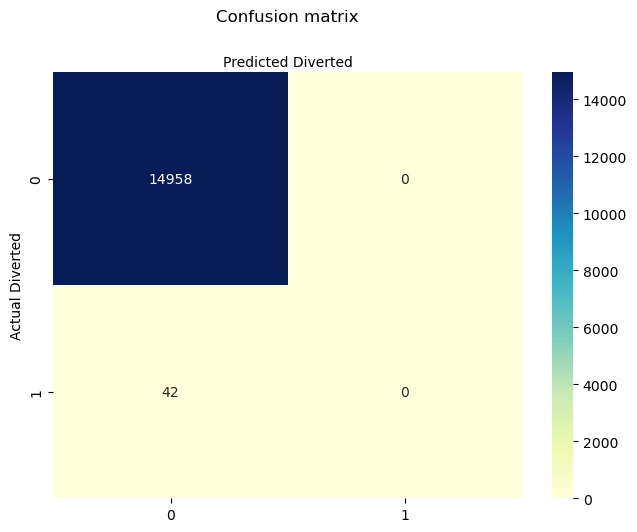

In [76]:
# Visualising Confusion Matrix
class_names = [0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

# Create Heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot = True, cmap = "YlGnBu", fmt = 'd')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y = 1.1)
plt.ylabel('Actual Diverted')
plt.xlabel('Predicted Diverted')

In [77]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
print("Precision:",metrics.precision_score(y_test, y_pred))
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.9972
Precision: 0.0
Recall: 0.0


/Applications/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.


This result show an inbalanced in the data used. Thus we could try to oversample the amount of diverted flights, to make it equal with the non-diverted one.

In [78]:
# Import the necessary libraries
import imblearn
from imblearn.over_sampling import SMOTE

# Creating an instance of SMOTE
smote = SMOTE()

X_resampled, y_resampled = smote.fit_resample(predictors, predicted)

In [79]:
# Split the data into training and test set
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size = 0.3,random_state = 1)

In [80]:
# Convert feature names to string type
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

# Fit the Logistic Regression model with the imputed data
logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_train, y_train)

# Use the trained model to make predictions

# Making predictions
y_pred = logreg.predict(X_test)

/Applications/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


In [81]:
# Confusion matrix
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[14042,   978],
       [  538, 14370]])

Text(0.5, 427.9555555555555, 'Predicted Diverted')

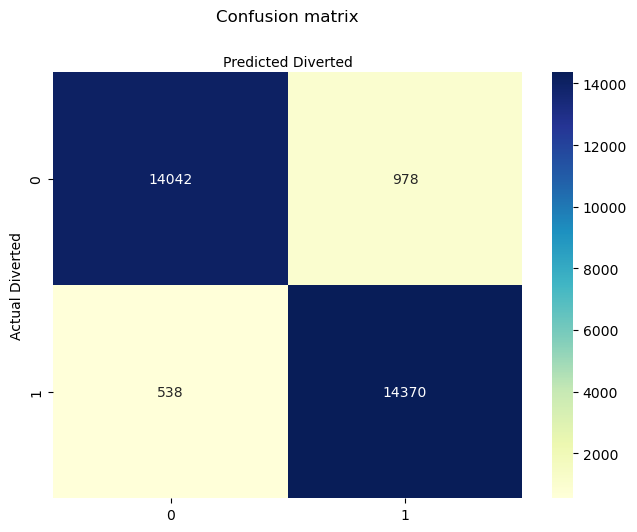

In [82]:
# Visualising Confusion Matrix
class_names = [0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

# Create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot = True, cmap = "YlGnBu", fmt = 'd')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y = 1.1)
plt.ylabel('Actual Diverted')
plt.xlabel('Predicted Diverted')

In [83]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
print("Precision:",metrics.precision_score(y_test, y_pred))
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.9493450948944132
Precision: 0.936278342455043
Recall: 0.9639119935605044


From the result of output number above, it shows that all of the metrics score exceeded 0.9. Hence, it can be concluded that the model is a good model in predicting diverted flight through few attributes.

For the final step, we will use ROC Curve to further evaluate the model. For a random classifier, it has an area under the curve of 0.5, while AUC for a perfect classifier is equal to 1.

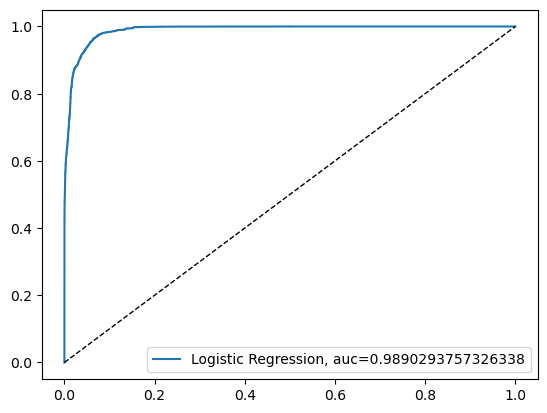

In [84]:
# ROC Curve
y_pred_proba = logreg.predict_proba(X_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label = "Logistic Regression, auc=" + str(auc))
plt.legend(loc = 4)
plt.plot([0, 1], [0, 1], color = 'black', lw = 1, linestyle = '--')
plt.show()

The output of the model's ROC Curve above shows that it has a very good value. Hence, the modelling process can be concluded.

### Conclusion

Even though the iteration is still not enough, we can still get enough data that makes a balanced confusion matrix. Based on the accuracy, precision, and recall, the model does a good job in predicting the diverted flights.